<div style=
   "background:linear-gradient(90deg, #0B5563, #1A8A9A);
    padding:25px;
    border-radius:15px;
    text-align:center;
    ">
<h1 style=
    "color:white;
     font-size:34px;
     margin:0;
     text-align:center !important;
     ">
     Bank Loan Default Risk Analysis
     </h1>
<p style=
   "color:#D4F1F4;
   font-size:16px; 
   margin:5px 0 0; 
   text-align:center !important;
   ">
   A Data Analytics project focused on understanding which borrower and loan characteristics are linked to loan default.
   </p>
   
</div>

## Data Domain Introduction

### Domain Overview
This project belongs to the **finance domain**, specifically **consumer lending and credit risk**. Lenders advance money to borrowers, who repay it with interest over a fixed period. The main risk in this business is that a borrower stops paying. A loan that the lender has given up on collecting is marked as **Charged Off**, and this project treats it as a **default**.

To manage this risk, lenders assess each applicant before approval and assign a **credit grade**. Riskier borrowers are charged higher interest rates to compensate for the higher chance of loss.

### Dataset Overview
The dataset contains consumer loans issued between **June 2007 and December 2011** on **LendingClub**, a US online lending platform. Each row represents one loan, and each column describes the borrower, the loan terms or the repayment outcome. Every loan has one of three outcomes:
- **Fully Paid:** the loan was repaid in full
- **Charged Off:** the borrower defaulted
- **Current:** the loan is still being repaid

### Business Importance
Understanding what drives default helps a lender decide who to approve, how to price loans and where to limit exposure. The analysis supports:
- **Credit policy:** setting approval rules
- **Risk-based pricing:** matching interest rates to risk
- **Loss forecasting:** estimating future write-offs

### Key Terms

| Term | Meaning |
|---|---|
| Default rate | Share of completed loans that ended as Charged Off |
| Grade (A-G) | Lender's risk rating; A is the lowest risk, G the highest |
| Term | Loan length, 36 or 60 months |
| Interest rate (`int_rate`) | Yearly cost of the loan to the borrower, in % |
| DTI (`dti`) | Debt-to-income ratio: monthly debt payments divided by monthly income (excluding mortgage) |
| Revolving utilisation (`revol_util`) | Share of available revolving credit (such as credit cards) that the borrower is using |
| Net return | Total payments received minus the amount funded (derived column) |

### Main Columns Used

| Column | Description |
|---|---|
| `loan_amnt`, `installment` | Amount borrowed and the monthly repayment |
| `annual_inc`, `emp_length`, `home_ownership` | Borrower income, years employed and housing status |
| `verification_status` | Whether the borrower's income was verified |
| `purpose`, `addr_state` | Reason for the loan and the borrower's US state |
| `issue_d` | Month the loan was issued |
| `earliest_cr_line` | Date the borrower's first credit line was opened |
| `delinq_2yrs`, `inq_last_6mths`, `pub_rec` | Past late payments, recent credit enquiries and public derogatory records |
| `total_pymnt` | Total amount paid back so far |
| `loan_status` | Fully Paid, Charged Off or Current |

### Tools and Methodology

This project is completed entirely using Python in Jupyter Notebook. The analysis will use Pandas and NumPy for data preparation and analysis, along with Matplotlib, Seaborn, and Plotly for visualisation.

The project follows these stages:

1. Data loading and initial inspection.
2. Data cleaning and preprocessing.
3. Exploratory data analysis.
4. Visualisation and statistical analysis.
5. Insight generation and recommendations

<div style="background-color:#C5E8EC; padding:20px; border-radius:12px; text-align:center; border-left:6px solid #1A8A9A;">
<h1 style="color:#0B5563; margin:0;">Phase 1: Data Loading and Initial Overview</h1>
</div>

#### Step 1.1: 🔹Import required libraries

In [46]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

#### Step 1.2: 🔹Load the dataset

In [47]:
# Load the raw file exactly as obtained (the sheet is named 'loan')
df = pd.read_csv("loan.csv")
df_raw_shape = df.shape   # keep for the before/after cleaning summary

#### Step 1.3: 🔹Confirm dataset shape

In [48]:
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")
df.dtypes.value_counts()

Rows: 39,717, Columns: 111


float64    74
str        24
int64      13
Name: count, dtype: int64

In [49]:
df.shape

(39717, 111)

#### Step 1.4: 🔹Inspect sample records

In [50]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
0,1077501,1296599,5000,5000,4975.0,36 months,10.65%,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-11,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0,Jan-85,1,NaN,NaN,3,0,13648,83.70%,9,f,0.00,0.00,5863.155187,5833.84,5000.00,863.16,0.00,0.00,0.00,Jan-15,171.62,NaN,May-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
1,1077430,1314167,2500,2500,2500.0,60 months,15.27%,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-11,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0,Apr-99,5,NaN,NaN,3,0,1687,9.40%,4,f,0.00,0.00,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-13,119.66,NaN,Sep-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
2,1077175,1313524,2400,2400,2400.0,36 months,15.96%,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-11,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,real estate business,606xx,IL,8.72,0,Nov-01,2,NaN,NaN,2,0,2956,98.50%,10,f,0.00,0.00,3005.666844,3005.67,2400.00,605.67,0.00,0.00,0.00,Jun-14,649.91,NaN,May-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,1076863,1277178,10000,10000,10000.0,36 months,13.49%,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-11,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0,Feb-96,1,35.0,NaN,10,0,5598,21%,37,f,0.00,0.00,12231.890000,12231.89,10000.00,2214.92,16.97,0.00,0.00,Jan-15,357.48,NaN,Apr-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

In [51]:
df.tail()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
39712,92187,92174,2500,2500,1075.0,36 months,8.07%,78.42,A,A4,FiSite Research,4 years,MORTGAGE,110000.0,Not Verified,Jul-07,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,Our current gutter system on our home is old a...,home_improvement,Home Improvement,802xx,CO,11.33,0,Nov-90,0,0.0,0.0,13,0,7274,13.10%,40,f,0.0,0.0,2822.969293,1213.88,2500.0,322.97,0.0,0.0,0.0,Jul-10,80.90,NaN,Jun-10,NaN,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39713,90665,90607,8500,8500,875.0,36 months,10.28%,275.38,C,C1,"Squarewave Solutions, Ltd.",3 years,RENT,18000.0,Not Verified,Jul-07,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,The rate of interest and fees incurred by carr...,credit_card,Retiring credit card debt,274xx,NC,6.40,1,Dec-86,1,5.0,0.0,6,0,8847,26.90%,9,f,0.0,0.0,9913.491822,1020.51,8500.0,1413.49,0.0,0.0,0.0,Jul-10,281.94,NaN,Jul-10,NaN,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39714,90395,90390,5000,5000,1325.0,36 months,8.07%,156.84,A,A4,NaN,< 1 year,MORTGAGE,100000.0,Not Verified,Jul-07,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,MBA Loan Consolidation,017xx,MA,2.30,0,Oct-98,0,0.0,0.0,11,0,9698,19.40%,20,f,0.0,0.0,5272.161128,1397.12,5000.0,272.16,0.0,0.0,0.0,Apr-08,0.00,NaN,Jun-07,NaN,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39715,90376,89243,5000,5000,650.0,36 months,7.43%,155.38,A,A2,NaN,< 1 year,MORTGAGE,200000.0,Not Verified,Jul-07,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,other,JAL Loan,208xx,MD,3.72,0,Nov-88,0,0.0,0.0,17,0,85607,0.70%,26,f,0.0,0.0,5174.198551,672.66,5000.0,174.20,0.0,0.0,0.0,Jan-08,0.00,NaN,Jun-07,NaN,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

#### Step 1.5:🔹Inspect data types

In [52]:
df.info(max_cols=0)   # compact info; full column list is in the dtype table below

<class 'pandas.DataFrame'>
RangeIndex: 39717 entries, 0 to 39716
Columns: 111 entries, id to total_il_high_credit_limit
dtypes: float64(74), int64(13), str(24)
memory usage: 52.6 MB


In [53]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 39717 entries, 0 to 39716
Data columns (total 111 columns):
 #    Column                          Non-Null Count  Dtype  
---   ------                          --------------  -----  
 0    id                              39717 non-null  int64  
 1    member_id                       39717 non-null  int64  
 2    loan_amnt                       39717 non-null  int64  
 3    funded_amnt                     39717 non-null  int64  
 4    funded_amnt_inv                 39717 non-null  float64
 5    term                            39717 non-null  str    
 6    int_rate                        39717 non-null  str    
 7    installment                     39717 non-null  float64
 8    grade                           39717 non-null  str    
 9    sub_grade                       39717 non-null  str    
 10   emp_title                       37258 non-null  str    
 11   emp_length                      38642 non-null  str    
 12   home_ownership             

#### Step 1.6:🔹Generate summary statistics

In [54]:
df.describe()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,total_acc,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_amnt,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
count,3.971700e+04,3.971700e+04,39717.000000,39717.000000,39717.000000,39717.000000,3.971700e+04,39717.000000,39717.000000,39717.000000,14035.000000,2786.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39717.000000,39661.0,0.0,39717.0,0.0,0.0,0.0,39717.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39661.0,39717.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39020.000000,39678.0,0.0,0.0,0.0,0.0
mean,6.831319e+05,8.504636e+05,11219.443815,10947.713196,10397.448868,324.561922,6.896893e+04,13.315130,0.146512,0.869200,35.900962,69.698134,9.294408,0.055065,13382.528086,22.088828,51.227887,50.989768,12153.596544,11567.149118,9793.348813,2263.663172,1.363015,95.221624,12.406112,2678.826162,0.0,NaN,1.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.043260,0.0,NaN,NaN,NaN,NaN
std,2.106941e+05,2.656783e+05,7456.670694,7187.238670,7128.450439,208.874874,6.379377e+04,6.678594,0.491812,1.070219,22.020060,43.822529,4.400282,0.237200,15885.016641,11.401709,375.172839,373.824457,9042.040766,8942.672613,7065.522127,2608.111964,7.289979,688.744771,148.671593,4447.136012,0.0,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.204324,0.0,NaN,NaN,NaN,NaN
min,5.473400e+04,7.069900e+04,500.000000,500.000000,0.000000,15.690000,4.000000e+03,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,NaN,1.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.0,NaN,NaN,NaN,NaN
25%,5.162210e+05,6.667800e+05,5500.000000,5400.000000,5000.000000,167.020000,4.040400e+04,8.170000,0.000000,0.000000,18.000000,22.000000,6.000000,0.000000,3703.000000,13.000000,0.000000,0.000000,5576.930000,5112.310000,4600.000000,662.180000,0.000000,0.000000,0.000000,218.680000,0.0,NaN,1.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N

#### Step 1.7:🔹Inspect categorical values

In [55]:
df['home_ownership'].unique()

<ArrowStringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER', 'NONE']
Length: 5, dtype: str

In [56]:
df['home_ownership'].value_counts()

home_ownership
RENT        18899
MORTGAGE    17659
OWN          3058
OTHER          98
NONE            3
Name: count, dtype: int64

In [57]:
df['verification_status'].unique()

<ArrowStringArray>
['Verified', 'Source Verified', 'Not Verified']
Length: 3, dtype: str

In [58]:
df['verification_status'].value_counts()

verification_status
Not Verified       16921
Verified           12809
Source Verified     9987
Name: count, dtype: int64

In [59]:
df['loan_status'].unique()

<ArrowStringArray>
['Fully Paid', 'Charged Off', 'Current']
Length: 3, dtype: str

In [60]:
df['loan_status'].value_counts()

loan_status
Fully Paid     32950
Charged Off     5627
Current         1140
Name: count, dtype: int64

**Initial observations**
- The raw file has **39,717 rows and 111 columns**.
- **54 columns are completely empty** and about 63 columns hold a single value (or nothing), so they carry no information and will be removed.
- `loan_status` has three values: *Fully Paid*, *Charged Off* and *Current*. Charged Off is the default outcome I will study.
- `int_rate` and `revol_util` are stored as fractions (0.1065), not percentages, and `term` and `emp_length` are text.
- `annual_inc` has extreme values (up to 6,000,000), so outliers need attention.
- `earliest_cr_line` has a maximum of 2046, which is impossible and looks like a two-digit-year parsing error.

<div style="background-color:#C5E8EC; padding:20px; border-radius:12px; text-align:center; border-left:6px solid #1A8A9A;">
<h1 style="color:#0B5563; margin:0;">Phase 2: Data Pre-processing</h1>
</div>

#### Step 2.1:🔄 Convert CSV text formats to numbers and dates

The CSV stores some values as text, such as percentages (`83.70%`) and dates (`Dec-11`). I convert them to numeric and date types so that calculations such as median, date differences and time-based analysis work correctly.

In [61]:
# Convert text columns to numbers and dates (safe to re-run)
for c in ["int_rate", "revol_util"]:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].str.strip().str.rstrip("%").astype(float) / 100

for c in ["issue_d", "earliest_cr_line", "last_pymnt_d", "next_pymnt_d", "last_credit_pull_d"]:
    if not pd.api.types.is_datetime64_any_dtype(df[c]):
        df[c] = pd.to_datetime(df[c], format="%b-%y", errors="coerce")

print(df["revol_util"].dtype, df["issue_d"].dtype)   # float64 and datetime64
df[["issue_d", "int_rate", "revol_util", "earliest_cr_line"]].head()

float64 datetime64[us]


,issue_d,int_rate,revol_util,earliest_cr_line
0,2011-12-01,0.1065,0.837,1985-01-01
1,2011-12-01,0.1527,0.094,1999-04-01
2,2011-12-01,0.1596,0.985,2001-11-01
3,2011-12-01,0.1349,0.210,1996-02-01
4,2011-12-01,0.1269,0.539,1996-01-01


#### Step 2.2:🧹 Remove empty, constant and non-analytical columns

Empty and single-value columns cannot explain differences between loans. Free-text and identifier-like columns (URL, description, employer title, loan title, ZIP prefix, member id) are also dropped because they are not suitable for the planned analysis

In [62]:
empty_cols = df.columns[df.isnull().all()].tolist()
const_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1 and c not in empty_cols]
text_cols = ["url", "desc", "emp_title", "title", "zip_code", "member_id"]

print(f"Empty columns: {len(empty_cols)} | Constant columns: {len(const_cols)}")
print("Constant columns:", const_cols)

df = df.drop(columns=empty_cols + const_cols + text_cols)
print("Shape after dropping:", df.shape)

Empty columns: 54 | Constant columns: 9
Constant columns: ['pymnt_plan', 'initial_list_status', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'chargeoff_within_12_mths', 'delinq_amnt', 'tax_liens']
Shape after dropping: (39717, 42)


#### Step 2.3:🔍Check Missing Values

In [63]:
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "missing_%": (missing/len(df)*100).round(2)}).query("missing > 0").sort_values("missing", ascending=False)

,missing,missing_%
next_pymnt_d,38577,97.13
mths_since_last_record,36931,92.99
mths_since_last_delinq,25682,64.66
emp_length,1075,2.71
pub_rec_bankruptcies,697,1.75
last_pymnt_d,71,0.18
revol_util,50,0.13
last_credit_pull_d,2,0.01


In [64]:
# mths_since_last_delinq / mths_since_last_record are blank mostly because the borrower
# has NO delinquency / public record, so blank is meaningful. Keep that as flags, then drop.
df["has_prior_delinq"] = df["mths_since_last_delinq"].notnull().astype(int)
df["has_public_record"] = df["mths_since_last_record"].notnull().astype(int)
df = df.drop(columns=["mths_since_last_delinq", "mths_since_last_record"])

# Categorical: employment length -> mode; numeric: median / mode
df["emp_length"] = df["emp_length"].fillna(df["emp_length"].mode()[0])
df["revol_util"] = df["revol_util"].fillna(df["revol_util"].median())
df["pub_rec_bankruptcies"] = df["pub_rec_bankruptcies"].fillna(df["pub_rec_bankruptcies"].mode()[0])

# next_pymnt_d is only filled for loans still 'Current', so it is blank for ~97% of rows. Drop it.
df = df.drop(columns=["next_pymnt_d"])

# Tiny gaps (<=73 rows in last_pymnt_d / last_credit_pull_d): drop remaining rows with missing values
before = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with remaining gaps | Missing values left: {df.isnull().sum().sum()}")

Dropped 73 rows with remaining gaps | Missing values left: 0


**Decisions:** blanks in the two "months since" columns mean *no event*, so I converted them to 0/1 flags instead of filling them. `emp_length` uses the mode (a category), `revol_util` the median (skewed numeric), and `pub_rec_bankruptcies` the mode (0). `next_pymnt_d` exists only for loans that are still *Current*, so it is blank for about 97% of rows and was dropped. The few rows left with gaps (under 0.2% of the data) are safe to drop.

#### Step 2.4:🔍Check Duplicate Records

In [65]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate loan ids:", df["id"].duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

Duplicate rows: 0
Duplicate loan ids: 0


#### Step 2.5:🔧 Correcting data types and formats

Some columns are stored in a form that is hard to analyse. I convert them so that calculations and charts work correctly:
- **`term`:** text such as `" 36 months"` becomes the number `36`
- **`emp_length`:** text such as `"< 1 year"` and `"10+ years"` becomes `0` and `10`
- **`int_rate` and `revol_util`:** fractions (`0.1065`) become percentages (`10.65`)
- **`earliest_cr_line`:** two-digit years read as 2046 are corrected to 1946
- **Text labels:** extra spaces are removed for consistency

In [66]:
# term: ' 36 months' -> 36
df["term"] = df["term"].str.extract(r"(\d+)").astype(int)

# emp_length: '< 1 year' -> 0, '10+ years' -> 10
df["emp_length"] = (df["emp_length"].str.replace("< 1 year", "0")
                    .str.extract(r"(\d+)")[0].astype(int))

# Rates stored as fractions -> percentages
df["int_rate"] = (df["int_rate"] * 100).round(2)
df["revol_util"] = (df["revol_util"] * 100).round(2)

# earliest_cr_line: years like 2046 are two-digit-year errors (should be 1946)
bad = df["earliest_cr_line"] > df["issue_d"]
print("Impossible credit-line dates fixed:", bad.sum())
df.loc[bad, "earliest_cr_line"] = df.loc[bad, "earliest_cr_line"] - pd.DateOffset(years=100)

# Consistent text labels
for c in ["grade", "sub_grade", "home_ownership", "verification_status", "loan_status", "purpose", "addr_state"]:
    df[c] = df[c].astype(str).str.strip()

df[["term","emp_length","int_rate","revol_util","earliest_cr_line"]].dtypes

Impossible credit-line dates fixed: 90


term                         int64
emp_length                   int64
int_rate                   float64
revol_util                 float64
earliest_cr_line    datetime64[us]
dtype: object

In [67]:
print("Latest credit-line date:", df["earliest_cr_line"].max())
print("Earliest credit-line date:", df["earliest_cr_line"].min())
print("Still after issue date:", (df["earliest_cr_line"] > df["issue_d"]).sum())

Latest credit-line date: 2008-11-01 00:00:00
Earliest credit-line date: 1946-01-01 00:00:00
Still after issue date: 0


- 90 credit-line dates were read in the wrong century (for example 2046 instead of 1946) and were corrected.
- After the fix, credit-line dates range from 1946 to 2008, and none fall after the loan issue date.

#### 2.6:🔹Derived columns

New columns are created from the existing data so that the analysis can answer the project question more directly:
- **`is_default`:** 1 if the loan was Charged Off, 0 if Fully Paid (blank for Current loans, because their outcome is not known yet)
- **`issue_year`, `issue_month`:** time features for trend analysis
- **`credit_history_years`:** how long the borrower had credit before the loan
- **`loan_to_income_%`:** loan amount as a percentage of annual income
- **`income_band`, `dti_band`, `loan_size_band`:** groups that make patterns easier to compare
- **`net_return`:** total payments received minus the amount funded

In [68]:
# Target: default flag (Charged Off = 1, Fully Paid = 0). 'Current' loans have no final outcome yet.
df["is_default"] = np.where(df["loan_status"] == "Charged Off", 1,
                   np.where(df["loan_status"] == "Fully Paid", 0, np.nan))

# Time features
df["issue_year"] = df["issue_d"].dt.year
df["issue_month"] = df["issue_d"].dt.month_name()
df["credit_history_years"] = ((df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25).round(1)

# Ratios and bands
df["loan_to_income_%"] = (df["loan_amnt"] / df["annual_inc"] * 100).round(2)
df["income_band"] = pd.cut(df["annual_inc"], bins=[0, 30000, 60000, 100000, np.inf],
                           labels=["<30K", "30-60K", "60-100K", "100K+"])
df["dti_band"] = pd.cut(df["dti"], bins=[-0.1, 10, 20, 30],
                        labels=["Low (0-10)", "Medium (10-20)", "High (20-30)"])
df["loan_size_band"] = pd.cut(df["loan_amnt"], bins=[0, 5000, 10000, 20000, 35000],
                              labels=["<=5K", "5-10K", "10-20K", "20-35K"])
df["net_return"] = df["total_pymnt"] - df["funded_amnt"]   # what the lender actually earned/lost

df[["is_default","issue_year","credit_history_years","loan_to_income_%","income_band","dti_band","net_return"]].head()

,is_default,issue_year,credit_history_years,loan_to_income_%,income_band,dti_band,net_return
0,0.0,2011,26.9,20.83,<30K,High (20-30),863.155187
1,1.0,2011,12.7,8.33,<30K,Low (0-10),-1491.290000
2,0.0,2011,10.1,19.59,<30K,Low (0-10),605.666844
3,0.0,2011,15.8,20.33,30-60K,Medium (10-20),2231.890000
4,NaN,2011,15.9,3.75,60-100K,Medium (10-20),513.330000


#### Step 2.7: Outliers

Outliers are values far from the rest of the data. In this dataset, `annual_inc` has a few extreme values (up to 6 million), which would stretch charts and distort averages. I detect them with the **IQR rule**: a value is an outlier if it lies more than 1.5 times the interquartile range above the third quartile.

I do **not** delete these rows, because very high incomes can be genuine borrowers. Instead I create a capped version of income (limited to the 99th percentile) for charts, and keep the original column unchanged.

In [69]:
q1, q3 = df["annual_inc"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"IQR upper fence: {upper:,.0f} | rows above it: {(df['annual_inc'] > upper).sum()}")
print(f"99th percentile: {df['annual_inc'].quantile(0.99):,.0f}")

df["annual_inc_capped"] = df["annual_inc"].clip(upper=df["annual_inc"].quantile(0.99))

IQR upper fence: 145,260 | rows above it: 1843
99th percentile: 235,000


#### 2.8: Filtering and aggregation (preview for EDA)

In [70]:
# Completed loans only (excluding 'Current') for default analysis
df_completed = df[df["loan_status"] != "Current"].copy()
print("Completed loans:", len(df_completed))

df_completed.groupby("grade")["is_default"].agg(loans="count", default_rate="mean").round(3)

Completed loans: 38504


,loans,default_rate
grade,,
A,10038,0.059
B,11660,0.121
C,7809,0.169
D,5072,0.218
E,2654,0.266
F,974,0.325
G,297,0.333


**Observations**
- 38,504 loans are completed (Fully Paid or Charged Off). The 1,140 Current loans are excluded from default analysis because their outcome is not yet known.
- Default rate rises steadily from about 5.9% for grade A to about 33% for grade G, so credit grade looks like a strong indicator of risk.

#### 2.9:🧹 Cleaning summary

This table records every cleaning decision, what problem it solved and the effect on the data.

| Step | Issue found | Action taken |
|---|---|---|
| Column removal | 54 columns were completely empty and 9 held a single value; 6 were free-text or identifier-like | Removed all of them (111 columns reduced to 42) |
| Missing values | Gaps in `emp_length`, `revol_util` and `pub_rec_bankruptcies`; many blanks in the two "months since" fields; `next_pymnt_d` blank for about 97% of rows | Mode or median fill; blanks in the "months since" fields converted to 0/1 flags; `next_pymnt_d` dropped; 73 remaining rows dropped |
| Duplicates | None found | Checked rows and loan ids |
| Data types and formats | Dates and percentages stored as text in the CSV; `term` and `emp_length` as text; 90 credit-line dates in the wrong century | Converted to numbers and dates; corrected the century error |
| Derived features | Not in the raw data | Added default flag, year and month, credit history, loan-to-income ratio, income, DTI and loan-size bands, and net return |
| Outliers | Income up to 6,000,000; 1,843 rows above the IQR fence | Kept all rows; created a capped column for charts |

In [71]:
print("Raw shape:  ", df_raw_shape)
print("Clean shape:", df.shape)
df.to_csv("loan_cleaned.csv", index=False)

Raw shape:   (39717, 111)
Clean shape: (39644, 51)


<div style="background-color:#C5E8EC; padding:20px; border-radius:12px; text-align:center; border-left:6px solid #1A8A9A;">
<h1 style="color:#0B5563; margin:0;">Phase 3: Exploratory Data Analysis (EDA)</h1>
</div>

In [72]:
# Prerequisite check: these must exist from the pre-processing phase
needed = ["is_default", "issue_year", "credit_history_years", "income_band", "dti_band",
          "loan_size_band", "net_return", "annual_inc_capped"]
missing = [c for c in needed if c not in df.columns]
print("Missing columns:", missing if missing else "none, ready for EDA")

# Completed loans only (safe to re-run)
df_completed = df[df["loan_status"] != "Current"].copy()
print("Completed loans:", len(df_completed))

Missing columns: none, ready for EDA
Completed loans: 38504


#### Exploratory Data Analysis (EDA) and Visualizations

Now that the data is clean, I explore it at three levels: **univariate** (one variable), **bivariate** (a variable against default) and **multivariate** (several variables together). Default rate means the share of *completed* loans (Fully Paid or Charged Off) that were Charged Off.

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

GRADE_ORDER = ["A", "B", "C", "D", "E", "F", "G"]

# One colour theme for the whole notebook (matches the teal banner)
# Rule: teal = volumes and distributions, orange = default / risk
TEAL_DARK, TEAL, TEAL_LIGHT, ORANGE = "#0B5563", "#1A8A9A", "#8CCFD8", "#E76F51"
GRADE_COLORS = sns.blend_palette([TEAL_DARK, ORANGE], 7)          # safe (A) to risky (G)
ORANGE_CMAP = LinearSegmentedColormap.from_list("risk", ["#FDEBE5", ORANGE, "#9C3A22"])
DIV_CMAP = LinearSegmentedColormap.from_list("teal_orange", [TEAL_DARK, "#F7F7F7", ORANGE])

overall_default = df_completed["is_default"].mean() * 100
print(f"Overall default rate (completed loans): {overall_default:.2f}%")

Overall default rate (completed loans): 14.43%


#### 3.1 Univariate analysis

**Visual 1: Distribution of key numeric variables.** Histograms show the shape, spread and skew of loan size, interest rate, income and debt-to-income ratio.

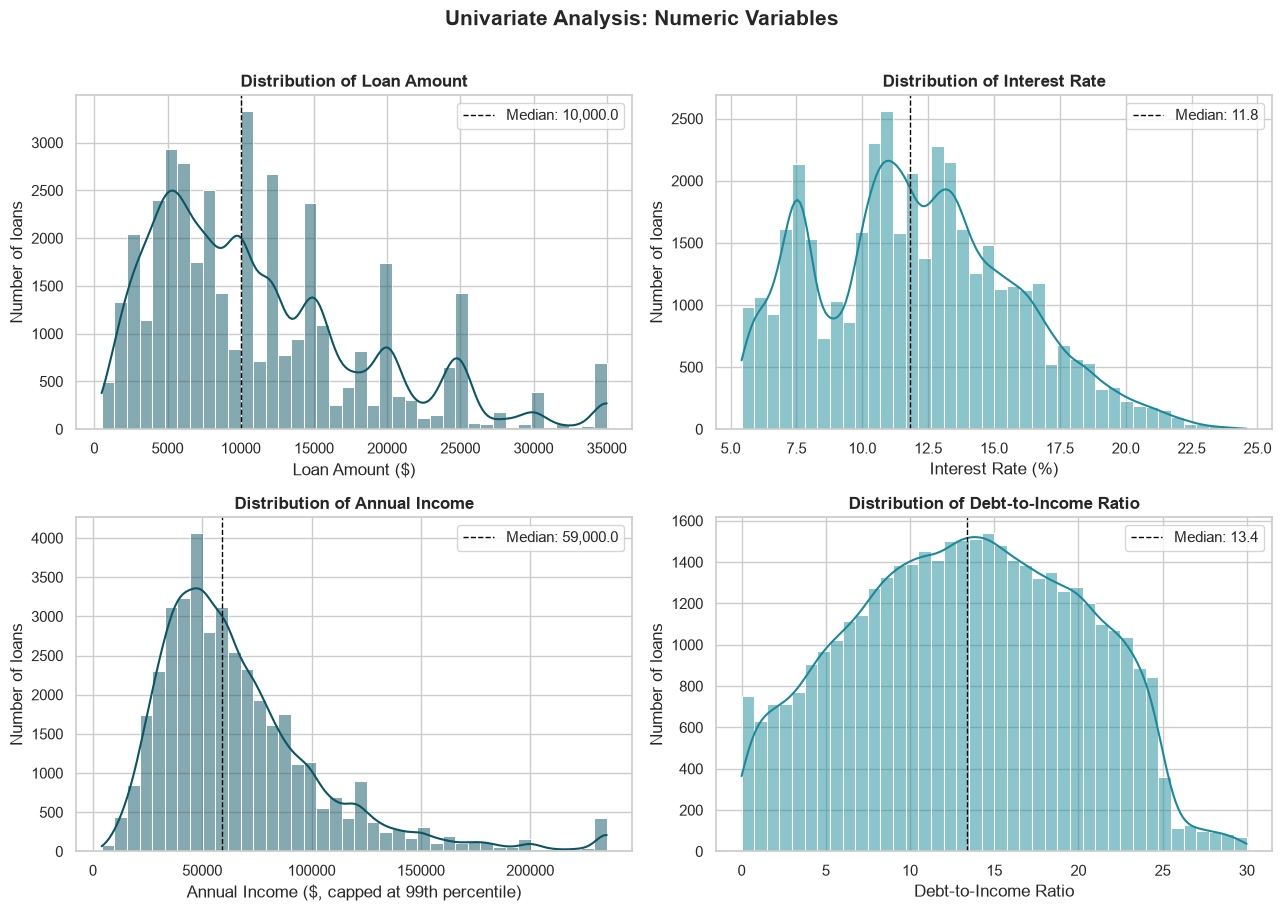

,loan_amnt,int_rate,annual_inc,dti
mean,11225.07,12.02,69008.32,13.32
median,10000.00,11.83,59000.00,13.41
std,7455.20,3.72,63834.81,6.68
skew,1.06,0.29,30.94,-0.03


In [74]:
num_plots = [("loan_amnt", "Loan Amount ($)", TEAL_DARK),
             ("int_rate", "Interest Rate (%)", TEAL),
             ("annual_inc_capped", "Annual Income ($, capped at 99th percentile)", TEAL_DARK),
             ("dti", "Debt-to-Income Ratio", TEAL)]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, label, color) in zip(axes.ravel(), num_plots):
    sns.histplot(df[col], bins=40, kde=True, color=color, ax=ax)
    ax.axvline(df[col].median(), color="black", linestyle="--", linewidth=1, label=f"Median: {df[col].median():,.1f}")
    ax.set_title(f"Distribution of {label.split(' (')[0]}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of loans")
    ax.legend()
plt.suptitle("Univariate Analysis: Numeric Variables", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

df[["loan_amnt", "int_rate", "annual_inc", "dti"]].agg(["mean", "median", "std", "skew"]).round(2)

  **Interpretation:**
- A typical loan is about 10,000 with an interest rate of about 12%.
- A typical borrower earns about 59,000 a year and has a debt-to-income ratio of about 13%.
- Loan amount and income have a few very large values. These pull the average above the middle value, so the median is a better "typical" figure than the mean.
- Income is the most extreme case. A few borrowers earn millions, so the average ($69,008) looks higher than what most people earn.
- Interest rate and DTI are balanced, because their average and median are almost the same.

**Visual 2: Loan status share and loan purpose .** A pie chart for the outcome, and a bar chart for what borrowers use the money for.

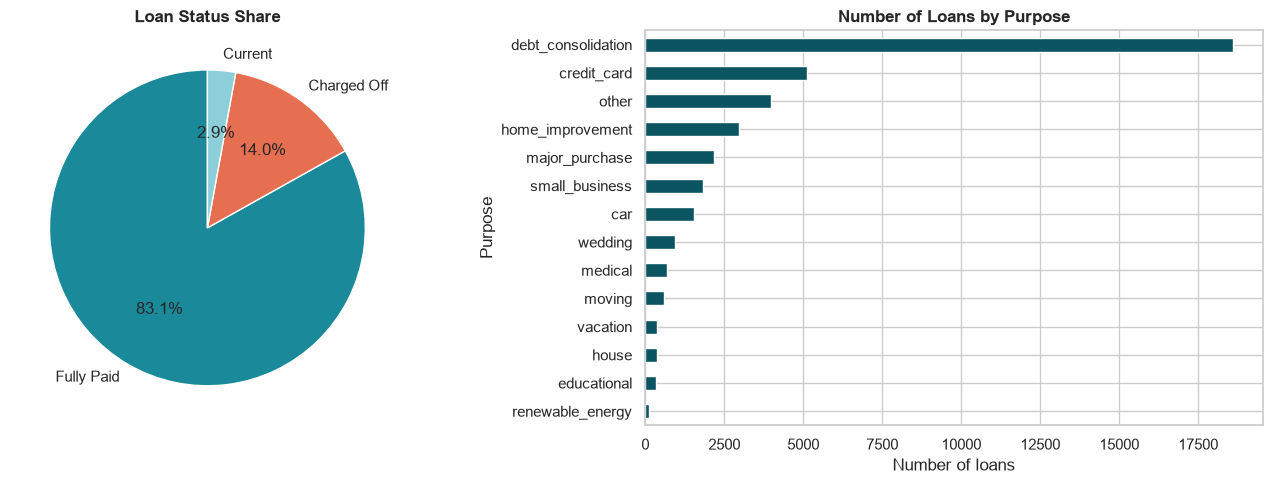

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

status = df["loan_status"].value_counts()
axes[0].pie(status, labels=status.index, autopct="%1.1f%%", startangle=90,
            colors=[TEAL, ORANGE, TEAL_LIGHT], wedgeprops={"edgecolor": "white"})
axes[0].set_title("Loan Status Share")

purpose = df["purpose"].value_counts().sort_values()
purpose.plot.barh(ax=axes[1], color=TEAL_DARK)
axes[1].set_title("Number of Loans by Purpose")
axes[1].set_xlabel("Number of loans")
axes[1].set_ylabel("Purpose")
plt.tight_layout()
plt.show()

**Interpretation:**
- About 83% of loans were fully paid and 14% were charged off, so most borrowers repay.
- Nearly half of all loans are for debt consolidation, so this purpose drives most of the lending volume.
- Credit card, home improvement and small business loans are common, while educational and renewable energy loans are very rare.

**Visual 3: Borrower profile.** Credit grade, loan term and home ownership show who the borrowers are.

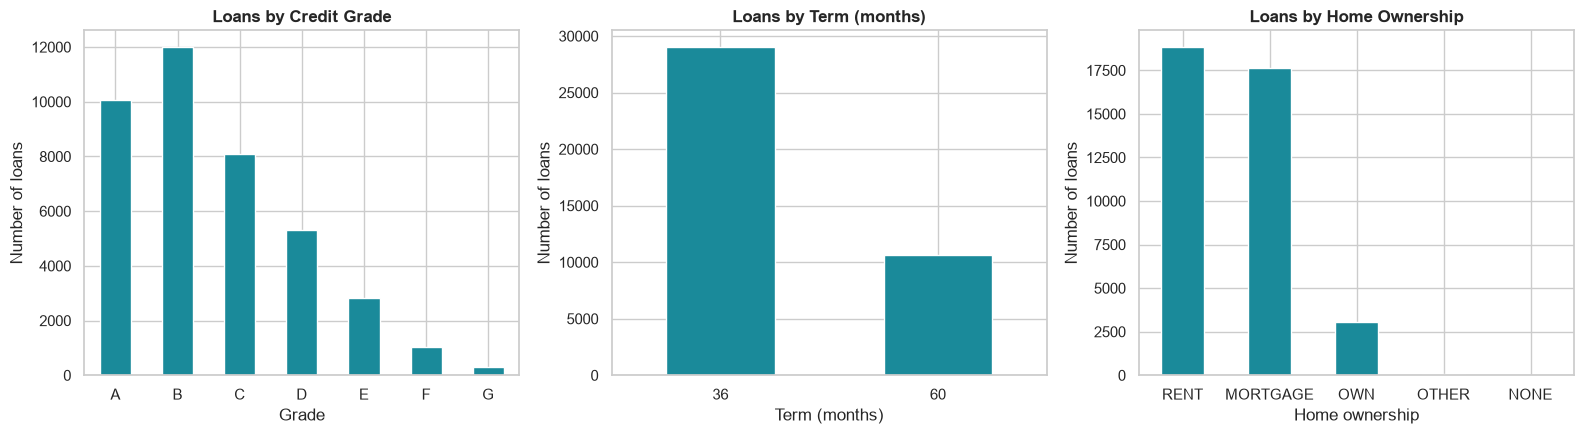

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df["grade"].value_counts().reindex(GRADE_ORDER).plot.bar(ax=axes[0], color=TEAL)
axes[0].set_title("Loans by Credit Grade")
axes[0].set_xlabel("Grade"); axes[0].set_ylabel("Number of loans")

df["term"].value_counts().plot.bar(ax=axes[1], color=TEAL)
axes[1].set_title("Loans by Term (months)")
axes[1].set_xlabel("Term (months)"); axes[1].set_ylabel("Number of loans")

df["home_ownership"].value_counts().plot.bar(ax=axes[2], color=TEAL)
axes[2].set_title("Loans by Home Ownership")
axes[2].set_xlabel("Home ownership"); axes[2].set_ylabel("Number of loans")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:**
- Most loans are in the better credit grades (A, B and C). Grades F and G are rare.
- About three quarters of the loans are 36-month loans, so 60-month loans are the smaller group.
- Most borrowers either rent or have a mortgage, and very few own their home outright.

#### 3.2 Bivariate analysis: what is linked to default?

**Visual 4: Interest rate and loan amount by credit grade.** Box plots show whether lenders charge more for riskier grades.

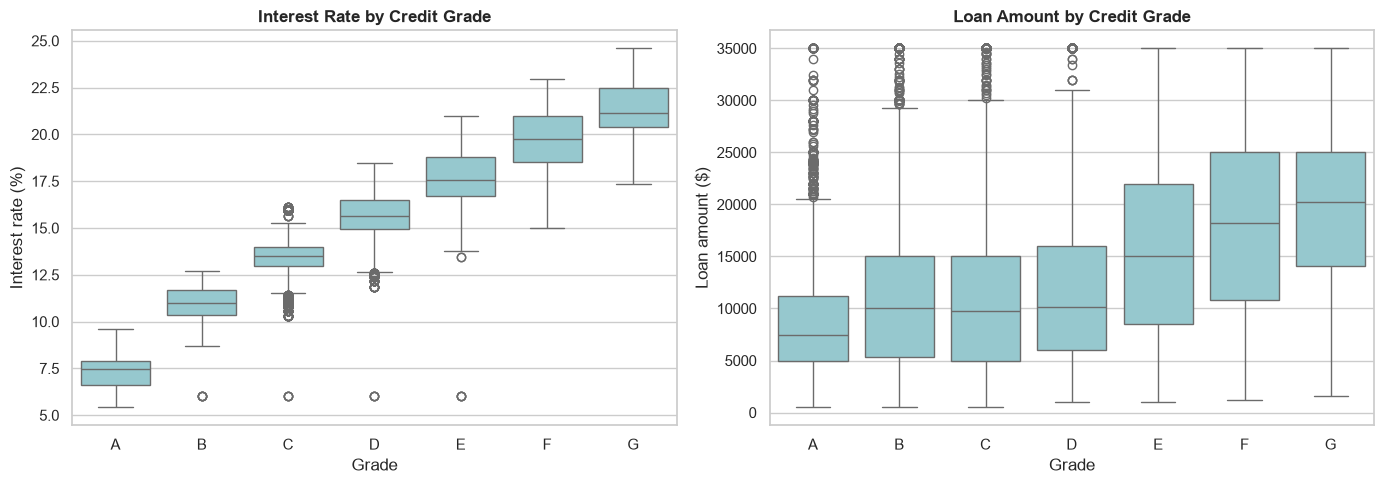

int_rate        loan_amnt         
          mean median      mean   median
grade                                   
A         7.33   7.49   8629.00   7500.0
B        11.02  10.99  11124.51  10000.0
C        13.55  13.49  11007.05   9750.0
D        15.72  15.65  12293.63  10137.5
E        17.71  17.56  15862.50  15000.0
F        19.75  19.74  18386.91  18200.0
G        21.40  21.14  20261.39  20250.0

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="grade", y="int_rate", order=GRADE_ORDER, color=TEAL_LIGHT, ax=axes[0])
axes[0].set_title("Interest Rate by Credit Grade")
axes[0].set_xlabel("Grade"); axes[0].set_ylabel("Interest rate (%)")

sns.boxplot(data=df, x="grade", y="loan_amnt", order=GRADE_ORDER, color=TEAL_LIGHT, ax=axes[1])
axes[1].set_title("Loan Amount by Credit Grade")
axes[1].set_xlabel("Grade"); axes[1].set_ylabel("Loan amount ($)")
plt.tight_layout()
plt.show()

df.groupby("grade")[["int_rate", "loan_amnt"]].agg(["mean", "median"]).round(2)

**Interpretation:**
- Interest rate rises steadily with credit grade, from about 7.5% for grade A to about 21% for grade G. Lenders charge higher rates for riskier borrowers.
- Loan amount also rises with grade. Riskier borrowers tend to take larger loans, from a typical $7,500 for grade A to about $20,000 for grade G.
- Grade A loans are the cheapest and smallest, while grades F and G are the most expensive and the largest.

**Visual 5: Default rate by credit grade.** The dashed line is the overall default rate.

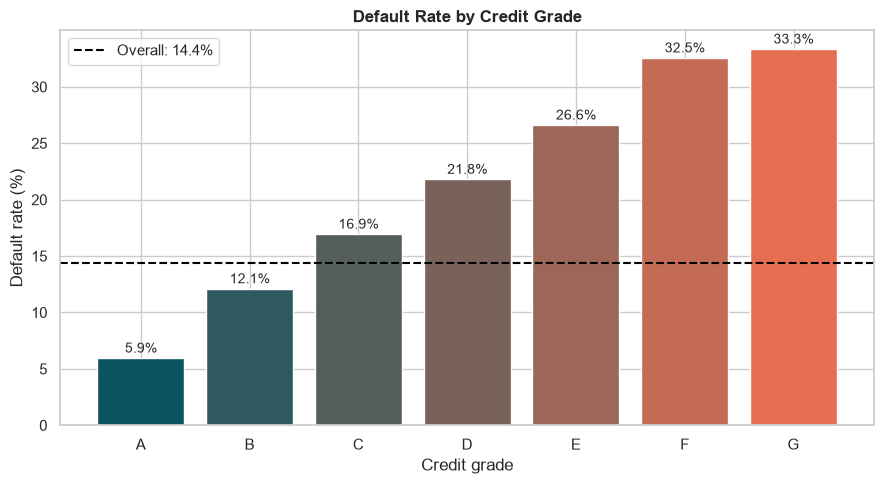

,loans,default_rate
grade,,
A,10038,5.94
B,11660,12.09
C,7809,16.93
D,5072,21.79
E,2654,26.60
F,974,32.55
G,297,33.33


In [78]:
grade_default = df_completed.groupby("grade")["is_default"].agg(loans="count", default_rate="mean")
grade_default["default_rate"] = (grade_default["default_rate"] * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(grade_default.index, grade_default["default_rate"], color=GRADE_COLORS)
ax.axhline(overall_default, color="black", linestyle="--", label=f"Overall: {overall_default:.1f}%")
for b, v in zip(bars, grade_default["default_rate"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_title("Default Rate by Credit Grade")
ax.set_xlabel("Credit grade"); ax.set_ylabel("Default rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

grade_default

**Interpretation:**
- The default rate rises steadily as credit grade gets worse, from about 5.9% for grade A to about 33% for grade G.
- Grades A and B are below the overall default rate of 14.4%, while grades C to G are above it.
- Credit grade is therefore a strong signal of risk. A grade G loan is about five to six times as likely to default as a grade A loan.

**Visual 6: Default rate by loan purpose.**

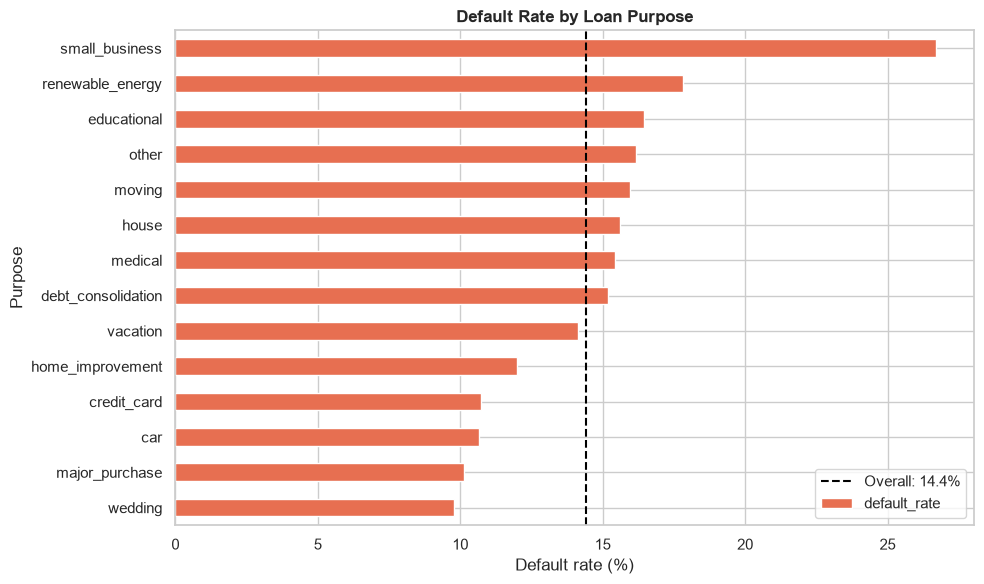

,loans,default_rate
purpose,,
small_business,1745,26.70
renewable_energy,101,17.82
educational,322,16.46
other,3854,16.17
moving,576,15.97
house,365,15.62
medical,680,15.44
debt_consolidation,18026,15.19
vacation,375,14.13


In [79]:
purpose_default = (df_completed.groupby("purpose")["is_default"].agg(loans="count", default_rate="mean"))
purpose_default["default_rate"] = (purpose_default["default_rate"] * 100).round(2)
purpose_default = purpose_default.sort_values("default_rate")

fig, ax = plt.subplots(figsize=(10, 6))
purpose_default["default_rate"].plot.barh(ax=ax, color=ORANGE)
ax.axvline(overall_default, color="black", linestyle="--", label=f"Overall: {overall_default:.1f}%")
ax.set_title("Default Rate by Loan Purpose")
ax.set_xlabel("Default rate (%)"); ax.set_ylabel("Purpose")
ax.legend()
plt.tight_layout()
plt.show()

purpose_default.sort_values("default_rate", ascending=False)

**Interpretation:**
- Small business loans are the riskiest, with a default rate of 26.7%, almost double the overall rate of 14.4%.
- Wedding, major purchase, car and credit card loans are the safest, with default rates of about 10%.
- Debt consolidation is the largest purpose and is slightly above average (15.2%), so it contributes the most to total defaults.
- Purposes with few loans, such as renewable energy, should be read with care because their rates are less reliable.

**Visual 7: Default rate by term, home ownership, income band and DTI band.** Four panels compare borrower and loan characteristics side by side.

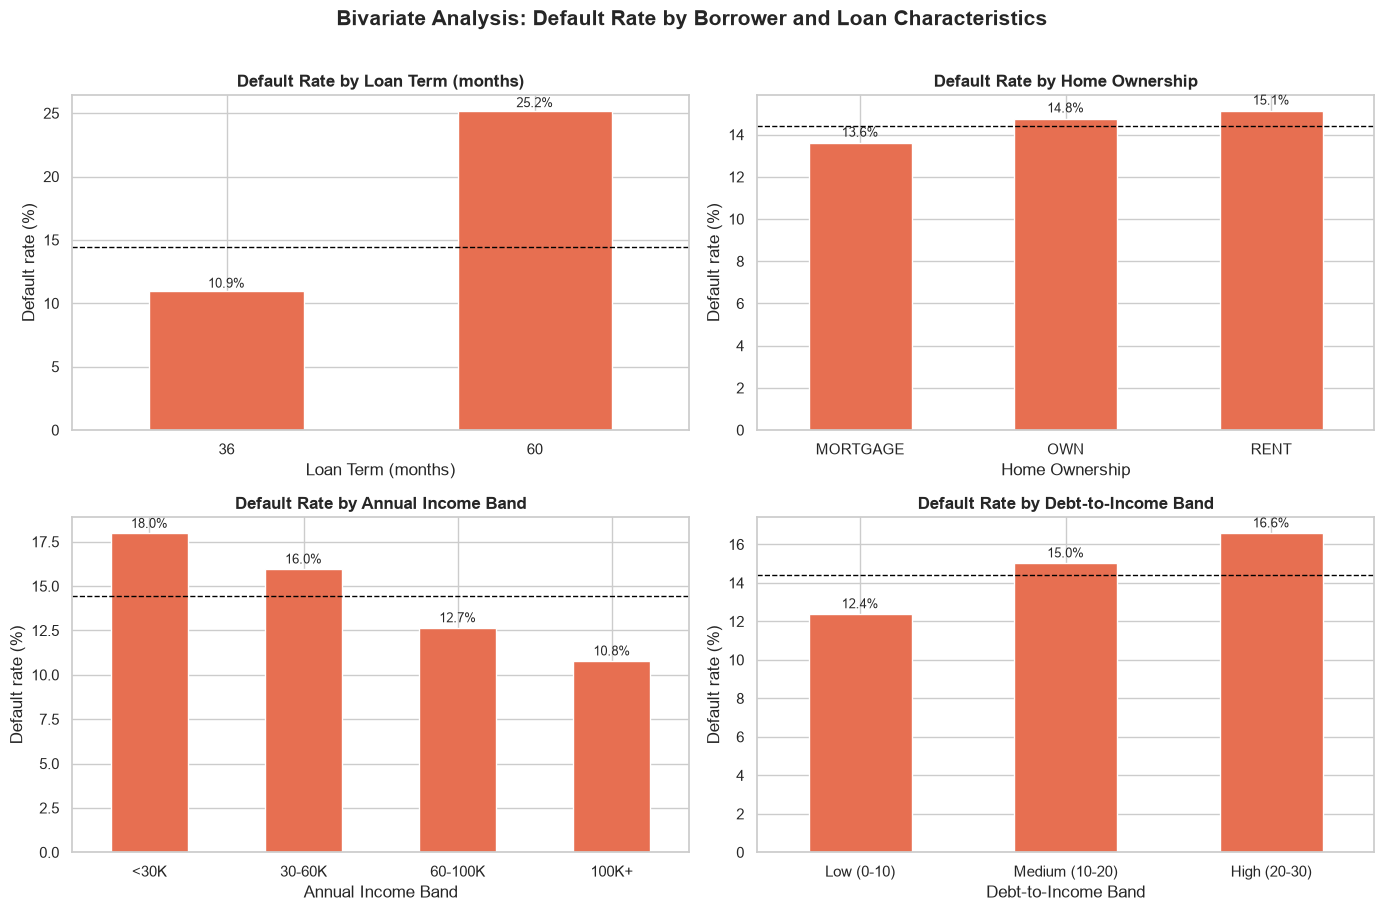

In [80]:
def default_rate(col, min_loans=100):
    # Ignore tiny groups (e.g. 3 loans with home ownership 'NONE') so rates are reliable
    g = df_completed.groupby(col, observed=True)["is_default"].agg(["count", "mean"])
    return (g[g["count"] >= min_loans]["mean"] * 100).round(2)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [("term", "Loan Term (months)", ORANGE),
          ("home_ownership", "Home Ownership", ORANGE),
          ("income_band", "Annual Income Band", ORANGE),
          ("dti_band", "Debt-to-Income Band", ORANGE)]

for ax, (col, label, color) in zip(axes.ravel(), panels):
    rates = default_rate(col)
    rates.plot.bar(ax=ax, color=color)
    ax.axhline(overall_default, color="black", linestyle="--", linewidth=1)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"Default Rate by {label}")
    ax.set_xlabel(label); ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Bivariate Analysis: Default Rate by Borrower and Loan Characteristics", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Interpretation:**
- 60-month loans default at about 25%, more than twice the rate of 36-month loans (about 11%), so longer loans are much riskier.
- Default falls as income rises, from 18% for borrowers earning under $30K to about 11% for those earning $100K or more.
- Default rises as the debt-to-income ratio rises, from 12.4% for low DTI to 16.6% for high DTI.
- Home ownership makes little difference, because renters, owners and borrowers with a mortgage all default at about the average rate.

**Visual 8: Default rate by verification status and loan size.**

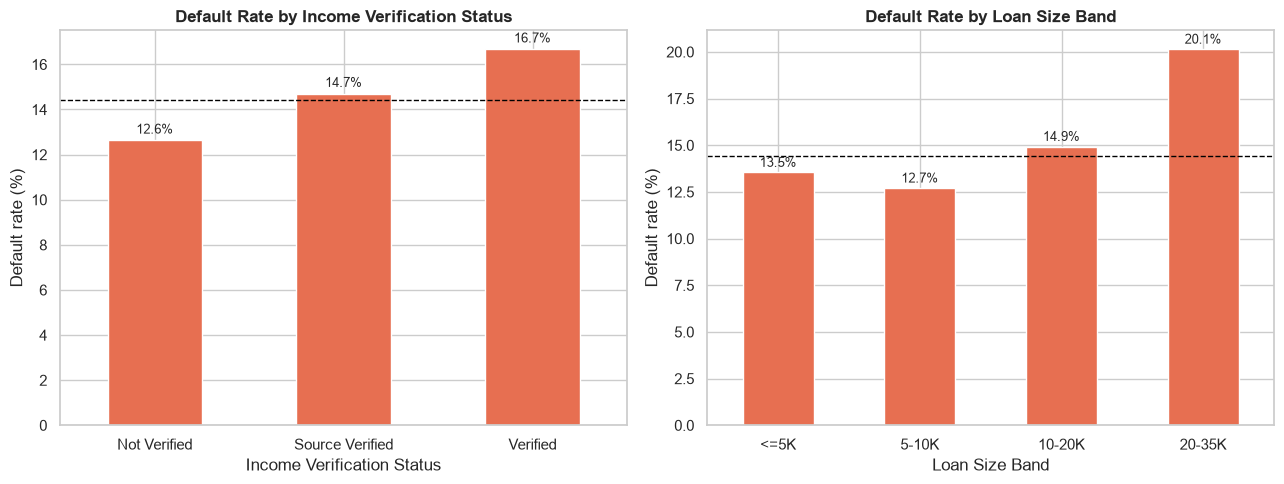

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (col, label, color) in zip(axes, [("verification_status", "Income Verification Status", ORANGE),
                                          ("loan_size_band", "Loan Size Band", ORANGE)]):
    rates = default_rate(col)
    rates.plot.bar(ax=ax, color=color)
    ax.axhline(overall_default, color="black", linestyle="--", linewidth=1)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"Default Rate by {label}")
    ax.set_xlabel(label); ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show() 

**Interpretation:**
- Loans with verified income default more (16.7%) than loans with unverified income (12.6%). This is probably because lenders verify the riskier or larger applications more often, so verification should not be treated as a safeguard on its own.
- The largest loans ($20K to $35K) have the highest default rate (20.1%), well above the smaller loan bands (12.7% to 14.9%).
- Lenders should be most careful with large loans.

**Visual 9: Default rate by state.** Only states with at least 300 completed loans are shown, so the rates are reliable.

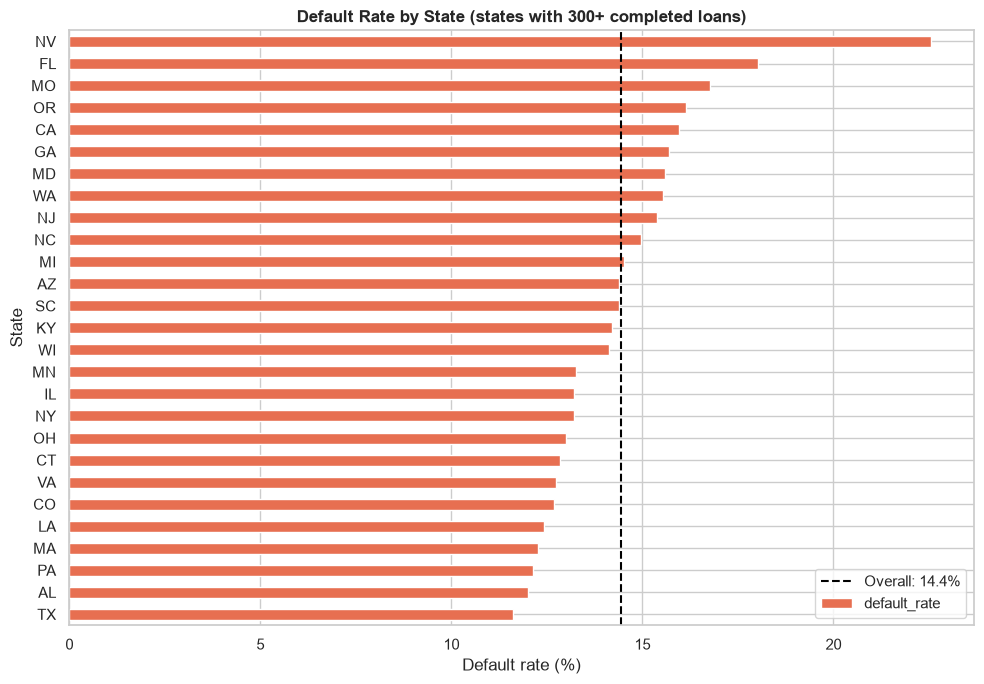

,loans,default_rate
addr_state,,
NV,479,22.55
FL,2778,18.03
MO,668,16.77
OR,434,16.13
CA,6928,15.95


In [82]:
state = df_completed.groupby("addr_state")["is_default"].agg(loans="count", default_rate="mean")
state = state[state["loans"] >= 300].copy()
state["default_rate"] = (state["default_rate"] * 100).round(2)
state = state.sort_values("default_rate")

fig, ax = plt.subplots(figsize=(10, 7))
state["default_rate"].plot.barh(ax=ax, color=ORANGE)
ax.axvline(overall_default, color="black", linestyle="--", label=f"Overall: {overall_default:.1f}%")
ax.set_title("Default Rate by State (states with 300+ completed loans)")
ax.set_xlabel("Default rate (%)"); ax.set_ylabel("State")
ax.legend()
plt.tight_layout()
plt.show()

state.sort_values("default_rate", ascending=False).head(5)

**Interpretation:**
- Default rates differ by state, from about 11.6% in Texas to 22.6% in Nevada.
- Nevada, Florida and Missouri have the highest default rates, while Texas, Alabama and Pennsylvania have the lowest.
- California and Florida have many loans and above-average default rates, so they matter most for total losses.
- Only states with at least 300 completed loans are shown, so the rates are reliable.

**Visual 10: Loan volume and default rate over time.** The left chart shows lending growth month by month, the right shows how the default rate changed by issue year.

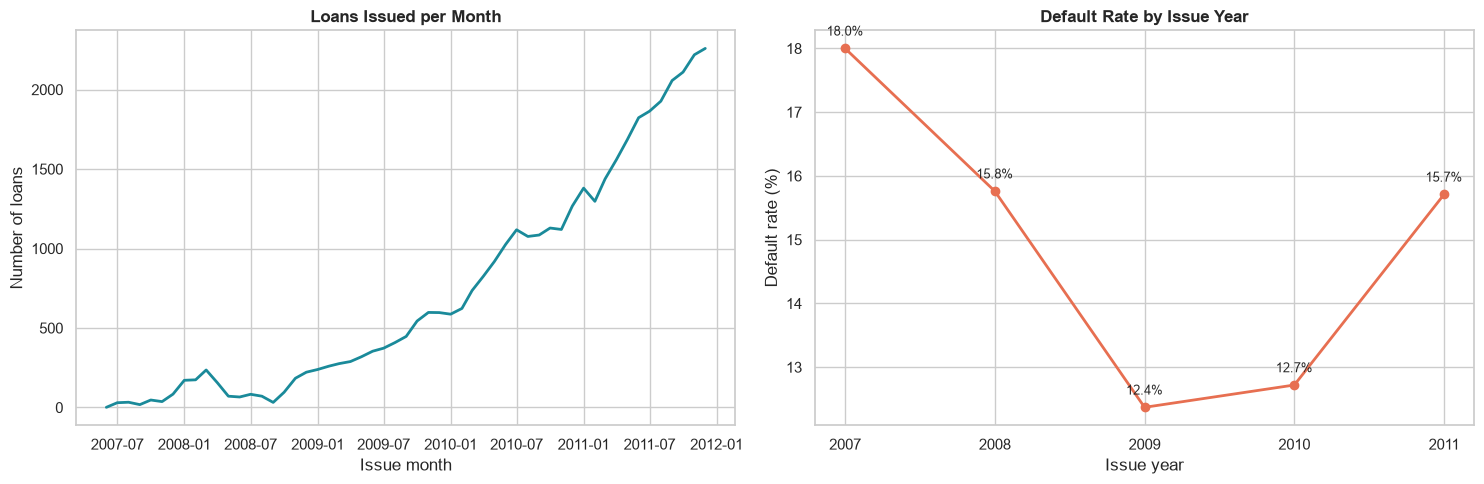

,loans,default_rate
issue_year,,
2007,250,18.00
2008,1561,15.76
2009,4704,12.37
2010,11511,12.72
2011,20478,15.71


In [83]:
monthly = df.groupby(df["issue_d"].dt.to_period("M")).size()
yearly = df_completed.groupby("issue_year")["is_default"].agg(loans="count", default_rate="mean")
yearly["default_rate"] = (yearly["default_rate"] * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(monthly.index.to_timestamp(), monthly.values, color=TEAL, linewidth=2)
axes[0].set_title("Loans Issued per Month")
axes[0].set_xlabel("Issue month"); axes[0].set_ylabel("Number of loans")

axes[1].plot(yearly.index, yearly["default_rate"], marker="o", color=ORANGE, linewidth=2)
for x, y in zip(yearly.index, yearly["default_rate"]):
    axes[1].text(x, y + 0.2, f"{y:.1f}%", ha="center", fontsize=9)
axes[1].set_title("Default Rate by Issue Year")
axes[1].set_xlabel("Issue year"); axes[1].set_ylabel("Default rate (%)")
axes[1].set_xticks(yearly.index)
plt.tight_layout()
plt.show()

yearly

**Interpretation:**
- Lending grew quickly, from a handful of loans in mid-2007 to more than 2,200 a month by the end of 2011, with a small dip in 2008.
- The default rate fell from 18.0% for loans issued in 2007 to about 12.4% in 2009 and 12.7% in 2010, then rose to 15.7% for 2011 loans.
- The 2007 figure is based on only 250 loans, and 2011 excludes loans still being repaid, so both should be read with care.

**Visual 11: Loan amount vs interest rate.** A random sample of 5,000 completed loans, coloured by outcome, shows whether defaults cluster at higher rates.

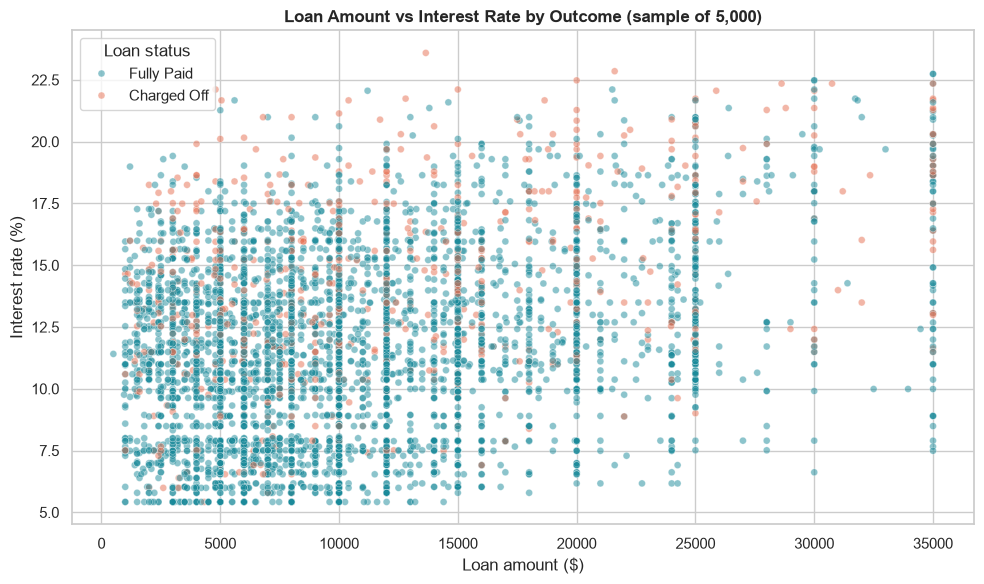

,loan_amnt,int_rate,dti,annual_inc,revol_util
loan_status,,,,,
Charged Off,12154.19,13.82,14.03,62632.87,55.63
Fully Paid,10866.76,11.61,13.15,69860.98,47.53


In [84]:
sample = df_completed.sample(5000, random_state=42)
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample, x="loan_amnt", y="int_rate", hue="loan_status",
                palette={"Fully Paid": TEAL, "Charged Off": ORANGE}, alpha=0.5, s=25, ax=ax)
ax.set_title("Loan Amount vs Interest Rate by Outcome (sample of 5,000)")
ax.set_xlabel("Loan amount ($)"); ax.set_ylabel("Interest rate (%)")
ax.legend(title="Loan status")
plt.tight_layout()
plt.show()

df_completed.groupby("loan_status")[["loan_amnt", "int_rate", "dti", "annual_inc", "revol_util"]].mean().round(2)

**Interpretation:**
- Charged-off loans carry a higher average interest rate (13.8% vs 11.6%) and are larger on average (\$12,154 vs \$10,867).
- They also have a higher DTI (14.0 vs 13.1), higher revolving utilisation (55.6% vs 47.5%) and lower income (\$62,633 vs \$69,861).
- In the scatter plot, orange and teal points overlap heavily. Defaults are more common at higher rates, but no single variable separates them cleanly.

#### 3.3 Pivot table analysis (tables only)

Pivot tables compare default rate, interest rate, loan counts and returns across **two variables at once**. They are shown as tables without charts.

**Pivot 1: Default rate (%) by loan purpose and term.** `Loans` is the number of completed loans for each purpose.

In [91]:
# Default rate (%) by purpose and term
p1 = df_completed.pivot_table(values="is_default", index="purpose", columns="term", aggfunc="mean") * 100
p1["All terms"] = df_completed.groupby("purpose")["is_default"].mean() * 100
p1["Loans"] = df_completed.groupby("purpose").size()
p1.round(1).sort_values("All terms", ascending=False)

term,36,60,All terms,Loans
purpose,,,,
small_business,21.3,39.6,26.7,1745
renewable_energy,17.1,20.0,17.8,101
educational,15.0,43.8,16.5,322
other,13.0,29.9,16.2,3854
moving,15.3,19.4,16.0,576
house,10.4,28.3,15.6,365
medical,13.3,22.9,15.4,680
debt_consolidation,11.0,26.3,15.2,18026
vacation,11.8,27.8,14.1,375


**Interpretation:**
- The 60-month default rate is higher than the 36-month rate for every purpose. For example, credit card loans default at 7.7% over 36 months and 23.9% over 60 months.
- Small business is the riskiest in both terms (21.3% and 39.6%), while wedding loans are among the safest (7.6% over 36 months).
- Debt consolidation, the largest purpose, goes from 11.0% to 26.3% when the term is longer.
- Some cells, such as educational and renewable energy, rest on few loans and should be read with care.

**Pivot 2: Default rate (%) and number of loans by income band and DTI band.**

In [92]:
# Default rate (%) and number of loans by income band and DTI band
p2_rate = df_completed.pivot_table(values="is_default", index="income_band", columns="dti_band",
                                   aggfunc="mean", observed=True) * 100
p2_loans = df_completed.pivot_table(values="is_default", index="income_band", columns="dti_band",
                                    aggfunc="count", observed=True)
pd.concat({"Default rate (%)": p2_rate.round(1), "Loans": p2_loans}, axis=1)

Default rate (%)                                  Loans                            
dti_band          Low (0-10) Medium (10-20) High (20-30) Low (0-10) Medium (10-20) High (20-30)
income_band                                                                                    
<30K                    17.0           19.0         17.6       1661           1962          903
30-60K                  13.8           16.4         17.9       4769           7941         3675
60-100K                 10.9           13.2         14.5       3989           6072         2053
100K+                    9.1           11.8         13.8       2481           2441          557

**Interpretation:**
- The riskiest group is borrowers earning under \\$30K with a medium DTI (19.0%), and the safest is borrowers earning \\$100K or more with a low DTI (9.1%), a gap of more than two times.
- Within every DTI column, default falls as income rises. Within every income band above \\$30K, default rises as DTI rises.
- For borrowers under \\$30K, DTI makes little difference (17.0%, 19.0%, 17.6%), so low income is the main risk there.

**Pivot 3: Average interest rate (%) by grade and term.**

In [93]:
# Average interest rate (%) by grade and term
p3 = df.pivot_table(values="int_rate", index="grade", columns="term", aggfunc="mean")
p3["Difference (60 - 36)"] = p3[60] - p3[36]
p3.round(2)

term,36,60,Difference (60 - 36)
grade,,,
A,7.33,7.50,0.18
B,11.00,11.11,0.11
C,13.47,13.75,0.28
D,15.36,16.27,0.91
E,16.96,18.04,1.07
F,18.59,20.04,1.46
G,20.33,21.64,1.31


**Interpretation:**
- For the same grade, 60-month loans carry only a slightly higher interest rate than 36-month loans. The difference is just 0.2 points for grade A and 1.5 points for grade F.
- Yet 60-month loans default several points more often in every grade (see the grade-by-term heatmap in the multivariate section). This suggests the extra risk of longer terms is priced only lightly.

**Pivot 4: Number of loans by issue year and grade.**

In [94]:
# Number of loans issued by year and grade
p4 = df.pivot_table(values="id", index="issue_year", columns="grade", aggfunc="count",
                    margins=True, margins_name="Total").fillna(0).astype(int)
p4

grade,A,B,C,D,E,F,G,Total
issue_year,,,,,,,,
2007,56,61,75,37,14,7,0,250
2008,295,507,438,222,75,20,4,1561
2009,1178,1362,1189,654,234,64,23,4704
2010,2801,3528,2456,1607,792,239,88,11511
2011,5748,6547,3915,2774,1718,717,199,21618
Total,10078,12005,8073,5294,2833,1047,314,39644


**Interpretation:**
- Lending grew in every grade, from 250 loans in 2007 to 21,618 in 2011.
- The riskier grades (D to G) made up about 21% of loans in 2008 and about 25% in 2011, so the mix moved slightly towards riskier borrowers.
- Grade G is very rare in the early years (0 in 2007 and 4 in 2008), which is why early default rates for the riskiest grades are unreliable.

**Pivot 5: Average net return per completed loan (\\$) by grade and term.** Net return is total payments received minus the amount funded.

In [95]:
# Average net return per completed loan ($) by grade and term
p5 = df_completed.pivot_table(values="net_return", index="grade", columns="term", aggfunc="mean")
p5.round(0)

term,36,60
grade,,
A,594.0,885.0
B,931.0,1439.0
C,954.0,1709.0
D,1240.0,1551.0
E,1533.0,2246.0
F,901.0,2526.0
G,662.0,3393.0


**Interpretation:**
- Average net return is positive for every grade and term, from about \$594 (grade A, 36 months) to \$3,393 (grade G, 60 months).
- 60-month loans earn more per loan than 36-month loans in every grade, because they pay interest for longer.
- Higher-risk grades earn more on average because of their high interest rates, even with more defaults. This ignores the lender's cost of funds, servicing costs and the time value of money, so it is not true profit.

#### 3.4 Multivariate analysis

**Visual 12: Default rate by grade and term (pivot heatmap).** This shows how two factors work together.

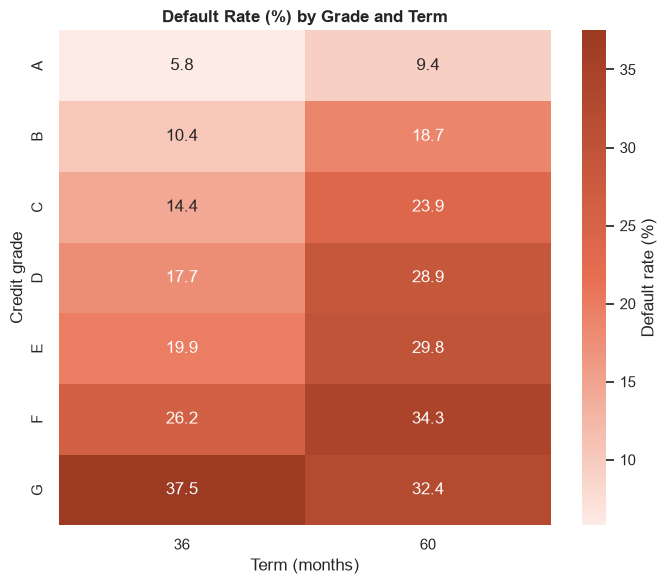

term,36,60
grade,,
A,5.8,9.4
B,10.4,18.7
C,14.4,23.9
D,17.7,28.9
E,19.9,29.8
F,26.2,34.3
G,37.5,32.4


In [85]:
pivot = (df_completed.pivot_table(values="is_default", index="grade", columns="term", aggfunc="mean") * 100).round(1)
pivot = pivot.reindex(GRADE_ORDER)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap=ORANGE_CMAP, cbar_kws={"label": "Default rate (%)"}, ax=ax)
ax.set_title("Default Rate (%) by Grade and Term")
ax.set_xlabel("Term (months)"); ax.set_ylabel("Credit grade")
plt.tight_layout()
plt.show()

pivot

**Interpretation:**
- For grades A to F, the 60-month default rate is higher than the 36-month rate. For grade C it is 23.9% against 14.4%, and for grade A it is 9.4% against 5.8%. So term adds risk beyond what the grade already shows.
- The lowest default rate is grade A with a 36-month term (5.8%). The highest reliable rate is grade F with a 60-month term (34.3%).
- Grade G looks reversed (37.5% for 36 months against 32.4% for 60 months), but only 56 grade G loans have a 36-month term, so this result is unreliable.

**Visual 13: Correlation heatmap.** Shows which numeric variables move together, and which are related to default.

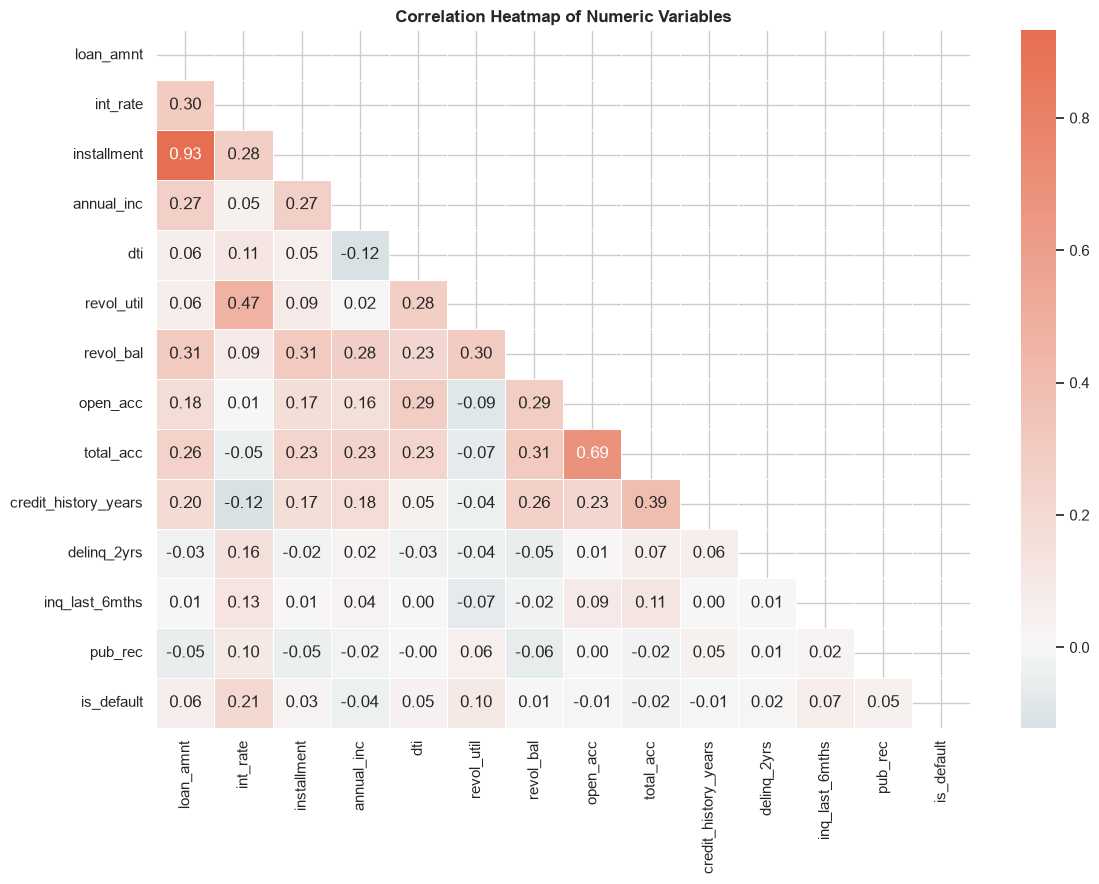

int_rate                0.210
revol_util              0.100
inq_last_6mths          0.071
loan_amnt               0.062
pub_rec                 0.051
dti                     0.046
installment             0.029
delinq_2yrs             0.019
revol_bal               0.008
open_acc               -0.007
credit_history_years   -0.013
total_acc              -0.020
annual_inc             -0.040
Name: is_default, dtype: float64

In [86]:
corr_cols = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "revol_util", "revol_bal",
             "open_acc", "total_acc", "credit_history_years", "delinq_2yrs", "inq_last_6mths", "pub_rec", "is_default"]
corr = df_completed[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

corr["is_default"].drop("is_default").sort_values(ascending=False).round(3)

**Interpretation:**
- All correlations with default are weak. The strongest is interest rate (0.21), followed by revolving utilisation (0.10) and recent credit enquiries (0.07). Annual income is slightly negative (-0.04), meaning higher income goes with fewer defaults.
- Strong links between other variables are expected: loan amount and installment (0.93) and open accounts and total accounts (0.69).
- No single numeric variable explains default on its own. Categories such as grade and term separate risk much better, as the earlier charts show.

**Visual 14: Default rate by grade over the years.** Checks whether the grade pattern holds in every year or changed over time.

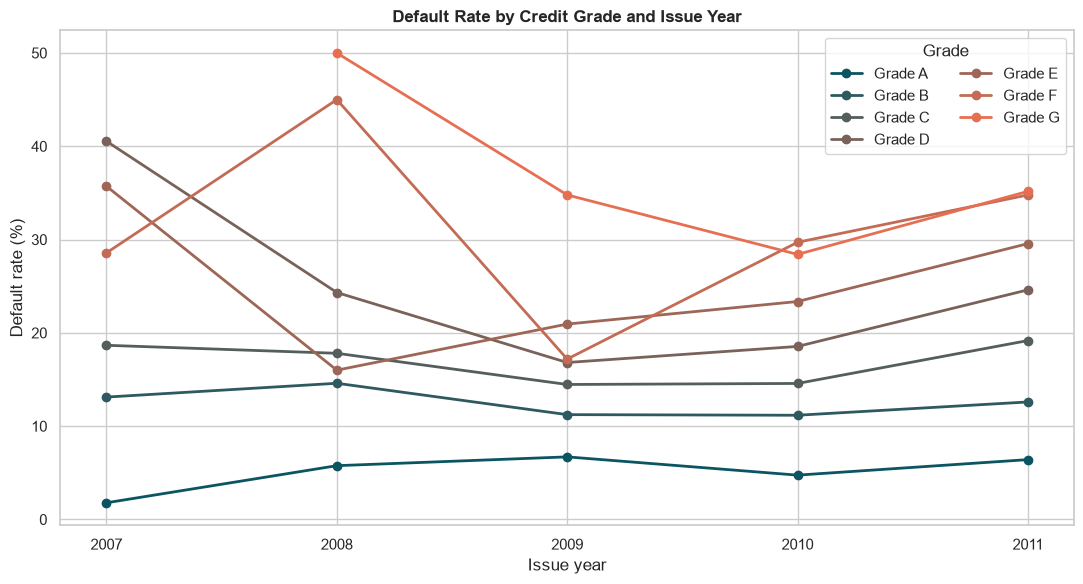

grade,A,B,C,D,E,F,G
issue_year,,,,,,,
2007,1.8,13.1,18.7,40.5,35.7,28.6,NaN
2008,5.8,14.6,17.8,24.3,16.0,45.0,50.0
2009,6.7,11.2,14.5,16.8,20.9,17.2,34.8
2010,4.7,11.2,14.6,18.5,23.4,29.7,28.4
2011,6.4,12.6,19.2,24.6,29.6,34.8,35.2


In [87]:
grade_year = (df_completed.pivot_table(values="is_default", index="issue_year", columns="grade", aggfunc="mean") * 100)
grade_year = grade_year[GRADE_ORDER]

fig, ax = plt.subplots(figsize=(11, 6))
for g, colr in zip(GRADE_ORDER, GRADE_COLORS):
    ax.plot(grade_year.index, grade_year[g], marker="o", label=f"Grade {g}", color=colr, linewidth=2)
ax.set_title("Default Rate by Credit Grade and Issue Year")
ax.set_xlabel("Issue year"); ax.set_ylabel("Default rate (%)")
ax.set_xticks(grade_year.index)
ax.legend(title="Grade", ncol=2)
plt.tight_layout()
plt.show()

grade_year.round(1)

**Interpretation:**
- Grade A has the lowest default rate in every year, so the ranking of the safest grade never changed.
- Lines for the riskier grades jump around in 2007 and 2008 because they are based on very few loans (for example only 4 grade G loans in 2008).
- From 2009 the lines are more stable and better ordered. In 2011, default rates rose for most grades (for example grade E at 29.6% and grade F at 34.8%), which matches the rise in the overall 2011 rate.

**Visual 15: Average net return per loan by grade (profitability).** `net_return` is total payments received minus the amount funded, so it shows what the lender actually earned or lost on completed loans.

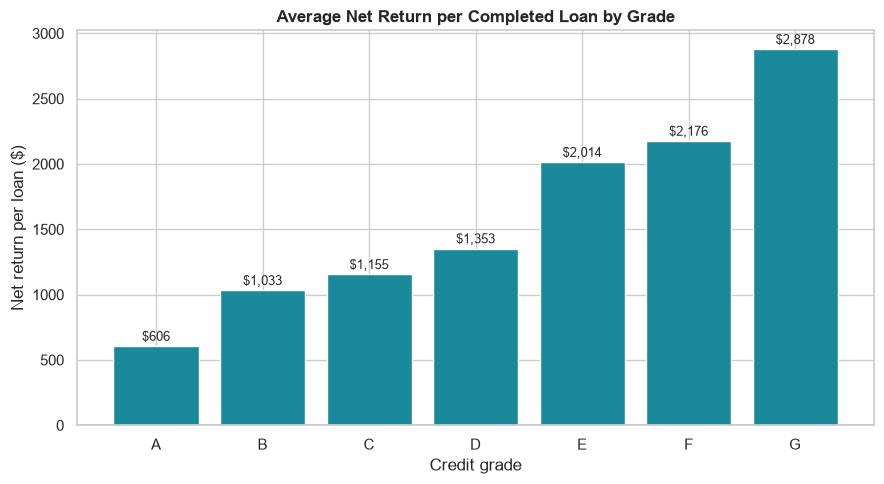

,default_rate,avg_net_return
grade,,
A,0.059,605.775
B,0.121,1032.739
C,0.169,1154.874
D,0.218,1353.161
E,0.266,2013.877
F,0.325,2175.858
G,0.333,2877.896


In [88]:
profit = df_completed.groupby("grade")["net_return"].mean().reindex(GRADE_ORDER).round(0)
fig, ax = plt.subplots(figsize=(9, 5))
colors = [TEAL if v >= 0 else ORANGE for v in profit.values]
ax.bar(profit.index, profit.values, color=colors)
for i, v in enumerate(profit.values):
    ax.text(i, v + (40 if v >= 0 else -120), f"${v:,.0f}", ha="center", fontsize=9)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Average Net Return per Completed Loan by Grade")
ax.set_xlabel("Credit grade"); ax.set_ylabel("Net return per loan ($)")
plt.tight_layout()
plt.show()

df_completed.groupby("grade")[["is_default", "net_return"]].agg(default_rate=("is_default", "mean"), avg_net_return=("net_return", "mean")).round(3)

**Interpretation:**
- Average net return is positive for every grade and rises from \$606 for grade A to \$2,878 for grade G.
- High interest on riskier loans more than makes up for their higher default rates on average.
- This ignores the lender's cost of funds and servicing costs, and it is an average, so individual defaulted loans still lost money.

### 3.4 Statistical summary
A chi-square test checks whether default is statistically linked to categorical variables (a p-value below 0.05 means the link is unlikely to be chance)

In [89]:
from scipy.stats import chi2_contingency

results = []
for col in ["grade", "term", "purpose", "home_ownership", "verification_status", "income_band", "dti_band"]:
    table = pd.crosstab(df_completed[col], df_completed["is_default"])
    chi2, p, dof, _ = chi2_contingency(table)
    results.append({"variable": col, "chi_square": round(chi2, 1), "p_value": p, "significant (p<0.05)": p < 0.05})

pd.DataFrame(results).sort_values("chi_square", ascending=False).reset_index(drop=True)

,variable,chi_square,p_value,significant (p<0.05)
0,grade,1563.2,0.000000e+00,True
1,term,1172.1,7.049807e-257,True
2,purpose,370.2,4.309589e-71,True
3,income_band,167.2,5.164284e-36,True
4,verification_status,93.5,4.970413e-21,True
5,dti_band,76.1,2.991226e-17,True
6,home_ownership,18.5,9.711732e-04,True


**Interpretation:**
- All seven variables are significantly linked to default (every p-value is below 0.05).
- The strongest links are credit grade (chi-square 1,563) and term (1,172). Home ownership is the weakest (18.5); it is statistically significant, but the difference in default rates is small.

Average of key measures for defaulted and fully paid loans:

In [90]:
# Average of key measures: defaulted vs fully paid loans
df_completed.groupby("loan_status")[["loan_amnt", "int_rate", "dti", "annual_inc", "revol_util", "credit_history_years"]].mean().round(2)

,loan_amnt,int_rate,dti,annual_inc,revol_util,credit_history_years
loan_status,,,,,,
Charged Off,12154.19,13.82,14.03,62632.87,55.63,13.51
Fully Paid,10866.76,11.61,13.15,69860.98,47.53,13.77


**Interpretation:** compared with fully paid loans, charged-off loans have a higher average loan amount, interest rate, DTI and revolving utilisation, and a lower average income.